<a href="https://colab.research.google.com/github/Mateuscruz19/HorrorMoviesData/blob/main/HorrorMovieAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Perguntas


1.   Como o número de lançamentos de terror variou por década entre 1950 e 2022, e como mudou a participação de filmes em idiomas diferentes do inglês?
2.   Filmes de terror com maior orçamento recebem avaliações médias maiores do público?
3. Entre os filmes com orçamento e receita informados, os de baixo orçamento apresentam retorno proporcional (receita/orçamento) maior que os de alto orçamento?
4. Quais gêneros aparecem com mais frequência combinados ao terror, e quais combinações têm melhor avaliação e popularidade?
5. Existe concentração de lançamentos em outubro (período do Halloween), e os filmes lançados nesse mês têm popularidade diferente dos demais?
6. Filmes que pertencem a uma franquia têm avaliação e receita diferentes de filmes avulsos?

# Preparacao do Ambiente

In [1]:
!git clone https://github.com/Mateuscruz19/HorrorMoviesData.git

fatal: destination path 'HorrorMoviesData' already exists and is not an empty directory.


In [2]:
# Bibliotecas para manipulação e visualização dos dados
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Configurações que deixam os resultados mais legíveis durante a aula
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

print("✓ Ambiente preparado.")

✓ Ambiente preparado.


# Inicializaçao/ Ingestao

In [3]:
URL_DADOS = "https://raw.githubusercontent.com/Mateuscruz19/HorrorMoviesData/refs/heads/main/horror_movies.csv"

try:
    df_original = pd.read_csv(URL_DADOS)
except Exception as erro:
    raise RuntimeError(
        "Não foi possível carregar a base. Verifique a conexão com a internet."
    ) from erro

print("✓ Dados carregados com sucesso!")
print(f"Fonte: {URL_DADOS}")
print(f"Shape: {df_original.shape[0]} linhas × {df_original.shape[1]} colunas")
print("\nPrimeiras linhas da base recebida:")
display(df_original.head())

✓ Dados carregados com sucesso!
Fonte: https://raw.githubusercontent.com/Mateuscruz19/HorrorMoviesData/refs/heads/main/horror_movies.csv
Shape: 32540 linhas × 21 colunas

Primeiras linhas da base recebida:


,Unnamed: 0,id,original_title,title,original_language,overview,tagline,release_date,poster_path,popularity,vote_count,vote_average,budget,revenue,runtime,status,adult,backdrop_path,genre_names,collection,collection_name
0,1,760161,Orphan: First Kill,Orphan: First Kill,en,After escaping from an Estonian psychiatric fa...,There's always been something wrong with Esther.,2022-07-27,/pHkKbIRoCe7zIFvqan9LFSaQAde.jpg,"5,088.58",902,6.90,0.00,"9,572,765.00",99,Released,False,/5GA3vV1aWWHTSDO5eno8V5zDo8r.jpg,"Horror, Thriller","760,193.00",Orphan Collection
1,2,760741,Beast,Beast,en,A recently widowed man and his two teenage dau...,Fight for family.,2022-08-11,/xIGr7UHsKf0URWmyyd5qFMAq4d8.jpg,"2,172.34",584,7.10,0.00,"56,000,000.00",93,Released,False,/2k9tBql5GYH328Krj66tDT9LtFZ.jpg,"Adventure, Drama, Horror",NaN,NaN
2,3,882598,Smile,Smile,en,"After witnessing a bizarre, traumatic incident...","Once you see it, it’s too late.",2022-09-23,/hiaeZKzwsk4y4atFhmncO5KRxeT.jpg,"1,863.63",114,6.80,"17,000,000.00","45,000,000.00",115,Released,False,/mVNPfpydornVe4H4UCIk7WevWjf.jpg,"Horror, Mystery, Thriller",NaN,NaN
3,4,756999,The Black Phone,The Black Phone,en,"Finney Blake, a shy but clever 13-year-old boy...",Never talk to strangers.,2022-06-22,/lr11mCT85T1JanlgjMuhs9nMht4.jpg,"1,071.40",2736,7.90,"18,800,000.00","161,000,000.00",103,Released,False,/AfvIjhDu9p64jKcmohS4hsPG95Q.jpg,"Horror, Thriller",NaN,NaN
4,5,772450,Presencias,Presences,es,A man who loses his wife and goes to seclude h...,NaN,2022-09-07,/dgDT3uol3mdvwEg0jt1ble3l9hw.jpg,"1,021.00",83,7.00,0.00,0.00,0,Released,False,/ojfzhdwRemcDt1I6pao6vVLw9AA.jpg,Horror,NaN,NaN


# Conhecimento

In [4]:
# Dicionário resumido das variáveis mais importantes para a demonstração
dicionario = pd.DataFrame({
    "coluna": [
        "Unnamed: 0", "id", "original_title", "title", "original_language",
        "overview", "tagline", "release_date", "poster_path", "popularity",
        "vote_count", "vote_average", "budget", "revenue", "runtime",
        "status", "adult", "backdrop_path", "genre_names", "collection",
        "collection_name"
    ],
    "significado": [
        "Número de linha do arquivo",
        "ID do filme no TMDB",
        "Título original",
        "Título internacional",
        "Idioma original",
        "Sinopse",
        "Slogan",
        "Data de lançamento",
        "Imagem do pôster",
        "Índice de popularidade",
        "Nº de votos",
        "Nota média (0 a 10)",
        "Orçamento",
        "Receita",
        "Duração (min)",
        "Situação de produção",
        "Conteúdo adulto(eita bixo🔞😳)",
        "Imagem de fundo",
        "Gêneros",
        "ID da coleção/franquia",
        "Nome da coleção/franquia"
    ],
})

display(dicionario.style.hide(axis="index"))

coluna,significado
Unnamed: 0,Número de linha do arquivo
id,ID do filme no TMDB
original_title,Título original
title,Título internacional
original_language,Idioma original
overview,Sinopse
tagline,Slogan
release_date,Data de lançamento
poster_path,Imagem do pôster
popularity,Índice de popularidade


# Inspecionar

A inspeção inicial responde perguntas básicas: qual é o tamanho da base, quais tipos foram inferidos, onde há valores ausentes e como os valores numéricos se distribuem?

Nesta etapa, ainda não alteramos nada.

In [5]:
print("VISÃO GERAL DA BASE ORIGINAL")
print("─" * 50)
print(f"Linhas:  {df_original.shape[0]}")
print(f"Colunas: {df_original.shape[1]}")
print(f"Células: {df_original.shape[0] * df_original.shape[1]:,}")

tipos = df_original.dtypes.astype(str).rename("tipo inferido").to_frame()
tipos.index.name = "coluna"
print("\nTipos inferidos pelo Pandas:")
display(tipos)

VISÃO GERAL DA BASE ORIGINAL
──────────────────────────────────────────────────
Linhas:  32540
Colunas: 21
Células: 683,340

Tipos inferidos pelo Pandas:


,tipo inferido
coluna,
Unnamed: 0,int64
id,int64
original_title,object
title,object
original_language,object
overview,object
tagline,object
release_date,object
poster_path,object


OBS: Blocos a seguir servem para identificar análises de possíveis problemas.
ex: colunas com muitos vazios, valores ausentes...
É importante para observar quais tipos de filtros devemos fazer pra nao quebrar tudo depois (ex: divisao por 0)

VALORES AUSENTES NA BASE ORIGINAL


,quantidade ausente,percentual ausente (%)
collection_name,30234,92.9%
collection,30234,92.9%
tagline,19836,61.0%
backdrop_path,18995,58.4%
poster_path,4474,13.7%
overview,1286,4.0%
original_language,0,0.0%
original_title,0,0.0%
id,0,0.0%
Unnamed: 0,0,0.0%


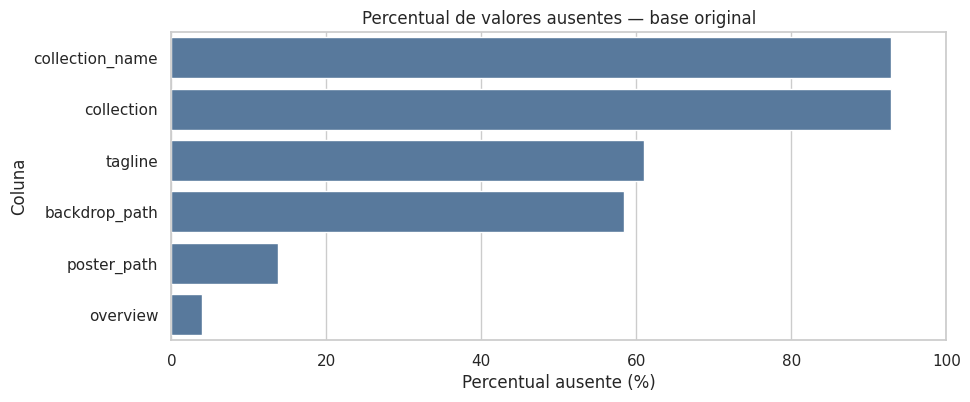

In [6]:
# Quantidade e percentual ajudam a avaliar a dimensão do problema
ausencias = pd.DataFrame({
    "quantidade ausente": df_original.isna().sum(),
    "percentual ausente (%)": df_original.isna().mean().mul(100)
}).sort_values("percentual ausente (%)", ascending=False)

print("VALORES AUSENTES NA BASE ORIGINAL")
display(ausencias.style.format({"percentual ausente (%)": "{:.1f}%"}))

# Mostramos apenas as colunas que realmente possuem ausências
ausencias_grafico = ausencias[ausencias["quantidade ausente"] > 0]
plt.figure(figsize=(10, 4))
sns.barplot(
    data=ausencias_grafico.reset_index(),
    x="percentual ausente (%)", y="index", color="#4C78A8"
)
plt.title("Percentual de valores ausentes — base original")
plt.xlabel("Percentual ausente (%)")
plt.ylabel("Coluna")
plt.xlim(0, 100)
plt.show()

In [7]:
print("ESTATÍSTICAS DAS COLUNAS NUMÉRICAS")
display(df_original.describe().T)

# Unnamed: 0 é sempre único, então fica de fora da comparação
linhas_iguais = int(df_original.drop(columns="Unnamed: 0").duplicated().sum())
print(f"\nLinhas com atributos observados iguais: {linhas_iguais}")
print("A duplicidade por id e por título + data é verificada em Q1, mais abaixo.")

ESTATÍSTICAS DAS COLUNAS NUMÉRICAS


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,"32,540.00","16,270.50","9,393.63",1.00,"8,135.75","16,270.50","24,405.25","32,540.00"
id,"32,540.00","445,910.83","305,744.67",17.00,"146,494.75","426,521.00","707,534.00","1,033,095.00"
popularity,"32,540.00",4.01,37.51,0.00,0.60,0.84,2.24,"5,088.58"
vote_count,"32,540.00",62.69,420.89,0.00,0.00,2.00,11.00,"16,900.00"
vote_average,"32,540.00",3.34,2.88,0.00,0.00,4.00,5.70,10.00
budget,"32,540.00","543,126.59","4,542,667.81",0.00,0.00,0.00,0.00,"200,000,000.00"
revenue,"32,540.00","1,349,746.73","14,430,479.15",0.00,0.00,0.00,0.00,"701,842,551.00"
runtime,"32,540.00",62.14,41.00,0.00,14.00,80.00,91.00,683.00
collection,"2,306.00","481,534.88","324,498.16",656.00,"155,421.00","471,259.00","759,067.25","1,033,032.00"



Linhas com atributos observados iguais: 0
A duplicidade por id e por título + data é verificada em Q1, mais abaixo.


# Avaliação da qualidade

Esta seção investiga os problemas da base antes da limpeza. Nada é alterado aqui: `df_original` continua igual ao arquivo lido.
Cada verificação tem um ID (Q1 a Q8), que é o mesmo usado no relatório e nas decisões de limpeza.

**Unidade de observação:** uma linha representa um filme cadastrado no TMDB com o gênero terror, no retrato coletado em outubro de 2022.

**Identificação dos registros:** a chave é `id` (identificador do filme no TMDB). `Unnamed: 0` é só o número da linha herdado da exportação e não identifica o filme.

In [8]:
# A base foi publicada no TidyTuesday em 01/11/2022; datas depois disso ainda não tinham acontecido na coleta
DATA_COLETA = pd.Timestamp("2022-11-01")
TOTAL = len(df_original)

datas = pd.to_datetime(df_original["release_date"], format="%Y-%m-%d", errors="coerce")
generos = df_original["genre_names"].str.split(", ")

# Guarda o resultado de cada verificação para o resumo no final da seção
diagnostico = {}

def registrar(qid, verificacao, resultado):
    diagnostico[(qid, verificacao)] = resultado

def pct(n):
    return f"{n:,} ({n / TOTAL:.1%})"

print("✓ Variáveis auxiliares prontas.")

✓ Variáveis auxiliares prontas.


## Dicionário com tipos e domínios

Complementa o dicionário acima com o tipo que o Pandas inferiu, o tipo esperado para cada atributo e o domínio observado.

In [9]:
tipo_esperado = {
    "Unnamed: 0": "inteiro (índice)", "id": "inteiro", "original_title": "texto", "title": "texto",
    "original_language": "categoria (ISO 639-1)", "overview": "texto", "tagline": "texto",
    "release_date": "data", "poster_path": "texto (caminho)", "popularity": "decimal ≥ 0",
    "vote_count": "inteiro ≥ 0", "vote_average": "decimal de 0 a 10", "budget": "inteiro ≥ 0 (US$)",
    "revenue": "inteiro ≥ 0 (US$)", "runtime": "inteiro > 0 (minutos)", "status": "categoria",
    "adult": "booleano", "backdrop_path": "texto (caminho)", "genre_names": "lista de categorias",
    "collection": "identificador", "collection_name": "texto",
}

def dominio(coluna):
    serie = df_original[coluna]
    if coluna == "release_date":
        return f"{datas.min():%Y-%m-%d} a {datas.max():%Y-%m-%d}"
    if pd.api.types.is_bool_dtype(serie):
        return ", ".join(map(str, serie.unique()))
    if pd.api.types.is_numeric_dtype(serie):
        return f"{serie.min():,.2f} a {serie.max():,.2f}"
    if serie.nunique() <= 10:
        return ", ".join(serie.dropna().unique())
    return "ex.: " + str(serie.dropna().iloc[0])[:40]

dicionario_tipos = pd.DataFrame({
    "coluna": df_original.columns,
    "tipo inferido": df_original.dtypes.astype(str).values,
    "tipo esperado": [tipo_esperado[c] for c in df_original.columns],
    "ausentes": df_original.isna().sum().values,
    "valores distintos": df_original.nunique().values,
    "domínio observado": [dominio(c) for c in df_original.columns],
})
display(dicionario_tipos.style.hide(axis="index"))

coluna,tipo inferido,tipo esperado,ausentes,valores distintos,domínio observado
Unnamed: 0,int64,inteiro (índice),0,32540,"1.00 a 32,540.00"
id,int64,inteiro,0,32540,"17.00 a 1,033,095.00"
original_title,object,texto,0,30296,ex.: Orphan: First Kill
title,object,texto,0,29563,ex.: Orphan: First Kill
original_language,object,categoria (ISO 639-1),0,97,ex.: en
overview,object,texto,1286,31020,ex.: After escaping from an Estonian psychiat
tagline,object,texto,19836,12512,ex.: There's always been something wrong with
release_date,object,data,0,10999,1950-01-01 a 2022-12-31
poster_path,object,texto (caminho),4474,28048,ex.: /pHkKbIRoCe7zIFvqan9LFSaQAde.jpg
popularity,float64,decimal ≥ 0,0,7250,"0.00 a 5,088.58"


## Q1 — Unicidade dos registros

Regras: `id` não pode se repetir; não pode haver linhas idênticas; e dois registros com o mesmo título e a mesma data de lançamento são candidatos a cadastro duplicado.

In [10]:
print("Q1 — UNICIDADE DOS REGISTROS")
print("─" * 50)

ids_repetidos = int(df_original["id"].duplicated().sum())
linhas_repetidas = int(df_original.drop(columns="Unnamed: 0").duplicated().sum())
mesmo_titulo_data = df_original[df_original.duplicated(["title", "release_date"], keep=False)]

print(f"ids repetidos: {ids_repetidos}")
print(f"linhas idênticas (sem Unnamed: 0): {linhas_repetidas}")
print(f"registros com mesmo título e data: {len(mesmo_titulo_data)} ({len(mesmo_titulo_data) // 2} pares)")
display(
    mesmo_titulo_data.sort_values(["title", "release_date"])
    [["id", "title", "release_date", "runtime", "vote_count", "overview"]]
)

registrar("Q1", "id repetido", ids_repetidos)
registrar("Q1", "linha idêntica (sem Unnamed: 0)", linhas_repetidas)
registrar("Q1", "mesmo título + data de lançamento", f"{len(mesmo_titulo_data)} registros em {len(mesmo_titulo_data) // 2} pares")

Q1 — UNICIDADE DOS REGISTROS
──────────────────────────────────────────────────


ids repetidos: 0
linhas idênticas (sem Unnamed: 0): 0
registros com mesmo título e data: 8 (4 pares)


,id,title,release_date,runtime,vote_count,overview
15991,323508,Angels Die Slowly,2010-02-01,86,0,"On a hot summer night in New Orleans, Angel an..."
31954,988409,Angels Die Slowly,2010-02-01,0,0,"On a hot summer night in New Orleans, Angel an..."
442,1017246,Cracked,2022-02-24,93,11,Ruja inherited the painting from her deceased ...
4531,821669,Cracked,2022-02-24,93,9,Ruja inherited a collection of paintings from ...
1415,581531,Metamorphosis,2019-08-21,113,154,An evil spirit that changes faces infiltrates ...
26522,669600,Metamorphosis,2019-08-21,0,1,NaN
5601,10042,Within,2005-01-01,95,27,8 explorers trapped in a Russian cave system a...
6861,360651,Within,2005-01-01,93,5,"Brad, Christina, T.K. and Kelly are on a post-..."


**Leitura:** a chave `id` é única e não há linhas copiadas. Dos 4 pares com mesmo título e data, *Cracked* e *Within* têm sinopses diferentes e são filmes distintos.
*Angels Die Slowly* tem a mesma sinopse nos dois registros, e um deles está com duração 0: é provavelmente o mesmo filme cadastrado duas vezes.
Em *Metamorphosis*, um registro não tem sinopse, tem 1 voto e duração 0, então não dá para confirmar se é o mesmo filme.
A duplicidade real é pequena (1 ou 2 registros) e não afeta as análises.

## Q2 — Valores ausentes explícitos (NaN)

Regra: para cada coluna com ausências, verificar se ela é usada nas perguntas e o que a ausência significa.

In [11]:
print("Q2 — VALORES AUSENTES EXPLÍCITOS")
print("─" * 50)

uso = {
    "overview": "não", "tagline": "não", "poster_path": "não", "backdrop_path": "não",
    "collection": "P6", "collection_name": "P6",
}
significado_ausencia = {
    "overview": "filme sem sinopse cadastrada",
    "tagline": "filme sem slogan cadastrado",
    "poster_path": "filme sem pôster",
    "backdrop_path": "filme sem imagem de fundo",
    "collection": "filme não pertence a uma franquia",
    "collection_name": "filme não pertence a uma franquia",
}
nulos = df_original.isna().sum()
nulos = nulos[nulos > 0]
ausentes_q2 = pd.DataFrame({
    "coluna": nulos.index,
    "ausentes": [pct(int(n)) for n in nulos.values],
    "usada nas perguntas": [uso[c] for c in nulos.index],
    "o que a ausência significa": [significado_ausencia[c] for c in nulos.index],
})
display(ausentes_q2.style.hide(axis="index"))

colunas_completas = [c for c in df_original.columns if c not in nulos.index]
print(f"Colunas sem nenhum NaN: {len(colunas_completas)} de {df_original.shape[1]}")

for coluna, n in nulos.items():
    registrar("Q2", f"NaN em {coluna}", pct(int(n)))

Q2 — VALORES AUSENTES EXPLÍCITOS
──────────────────────────────────────────────────


coluna,ausentes,usada nas perguntas,o que a ausência significa
overview,"1,286 (4.0%)",não,filme sem sinopse cadastrada
tagline,"19,836 (61.0%)",não,filme sem slogan cadastrado
poster_path,"4,474 (13.7%)",não,filme sem pôster
backdrop_path,"18,995 (58.4%)",não,filme sem imagem de fundo
collection,"30,234 (92.9%)",P6,filme não pertence a uma franquia
collection_name,"30,234 (92.9%)",P6,filme não pertence a uma franquia


Colunas sem nenhum NaN: 15 de 21


**Leitura:** as ausências explícitas estão só em colunas de texto e imagem, que não entram nas perguntas, e em `collection`/`collection_name`.
Nestas duas, NaN não é dado faltando: significa que o filme é avulso (não pertence a uma franquia), e é exatamente o grupo de comparação de P6.
Nenhuma dessas ausências precisa ser preenchida. O problema maior de ausência está escondido nos zeros (Q3).

## Q3 — Ausências disfarçadas de zero

O TMDB grava 0 quando o campo não foi informado. Um filme não tem orçamento de US$ 0 nem duração de 0 minutos, e nota 0 sem nenhum voto quer dizer "sem avaliação".
Regra: contar os zeros em cada atributo numérico usado nas perguntas.

In [12]:
print("Q3 — AUSÊNCIAS DISFARÇADAS DE ZERO")
print("─" * 50)

sem_votos = df_original["vote_count"] == 0
regras_zero = {
    "budget = 0": df_original["budget"] == 0,
    "revenue = 0": df_original["revenue"] == 0,
    "budget = 0 ou revenue = 0": (df_original["budget"] == 0) | (df_original["revenue"] == 0),
    "runtime = 0": df_original["runtime"] == 0,
    "vote_count = 0 (nenhum voto)": sem_votos,
    "vote_average = 0 e vote_count = 0": sem_votos & (df_original["vote_average"] == 0),
    "popularity = 0": df_original["popularity"] == 0,
}
zeros_q3 = pd.DataFrame({
    "regra": list(regras_zero),
    "registros": [pct(int(m.sum())) for m in regras_zero.values()],
})
display(zeros_q3.style.hide(axis="index"))

com_financeiro = int(((df_original["budget"] > 0) & (df_original["revenue"] > 0)).sum())
print(f"Filmes com orçamento E receita informados (base de P3): {pct(com_financeiro)}")

for regra, mascara in regras_zero.items():
    registrar("Q3", regra, pct(int(mascara.sum())))
registrar("Q3", "budget > 0 e revenue > 0 (base de P3)", pct(com_financeiro))

Q3 — AUSÊNCIAS DISFARÇADAS DE ZERO
──────────────────────────────────────────────────


regra,registros
budget = 0,"27,339 (84.0%)"
revenue = 0,"30,964 (95.2%)"
budget = 0 ou revenue = 0,"31,442 (96.6%)"
runtime = 0,"2,668 (8.2%)"
vote_count = 0 (nenhum voto),"11,602 (35.7%)"
vote_average = 0 e vote_count = 0,"11,590 (35.6%)"
popularity = 0,2 (0.0%)


Filmes com orçamento E receita informados (base de P3): 1,098 (3.4%)


**Leitura:** este é o problema mais grave da base. 84% dos filmes não têm orçamento e 95% não têm receita, e só 1.098 filmes (3,4%) têm os dois, que é a base possível para P3.
Cerca de 8% dos filmes têm duração 0, e um terço não recebeu nenhum voto, o que faz o `vote_average` 0 aparecer como se fosse uma nota real.
Se esses zeros forem usados como valores, médias de orçamento, nota e duração ficam puxadas para baixo e a divisão receita/orçamento quebra (divisão por zero).

## Q4 — Tipos de dados

Regra: comparar o tipo inferido com o esperado e testar se os valores podem ser convertidos sem perda.

In [13]:
print("Q4 — TIPOS DE DADOS")
print("─" * 50)

def inteiros(serie):
    serie = serie.dropna()
    return bool((serie % 1 == 0).all())

tipos_q4 = pd.DataFrame([
    {"coluna": "release_date", "tipo inferido": str(df_original["release_date"].dtype), "esperado": "data",
     "teste": "converte no formato AAAA-MM-DD", "falhas": int(datas.isna().sum())},
    {"coluna": "collection", "tipo inferido": str(df_original["collection"].dtype), "esperado": "identificador",
     "teste": "todos os valores são inteiros", "falhas": int((~(df_original["collection"].dropna() % 1 == 0)).sum())},
    {"coluna": "budget", "tipo inferido": str(df_original["budget"].dtype), "esperado": "inteiro",
     "teste": "todos os valores são inteiros", "falhas": int((~(df_original["budget"] % 1 == 0)).sum())},
    {"coluna": "revenue", "tipo inferido": str(df_original["revenue"].dtype), "esperado": "inteiro",
     "teste": "todos os valores são inteiros", "falhas": int((~(df_original["revenue"] % 1 == 0)).sum())},
    {"coluna": "adult", "tipo inferido": str(df_original["adult"].dtype), "esperado": "booleano",
     "teste": "valores distintos", "falhas": int(df_original["adult"].nunique())},
    {"coluna": "Unnamed: 0", "tipo inferido": str(df_original["Unnamed: 0"].dtype), "esperado": "índice",
     "teste": "é a sequência 1..n", "falhas": int((df_original["Unnamed: 0"] != np.arange(1, TOTAL + 1)).sum())},
])
display(tipos_q4.style.hide(axis="index"))

registrar("Q4", "release_date como texto", f"tipo {df_original['release_date'].dtype}; {int(datas.isna().sum())} falhas ao converter para data")
registrar("Q4", "collection como decimal", f"tipo {df_original['collection'].dtype} por causa dos NaN; todos os valores são inteiros")
registrar("Q4", "budget e revenue como decimal", "todos os valores são inteiros")
registrar("Q4", "adult", f"um único valor ({df_original['adult'].unique()[0]}) em todas as linhas")
registrar("Q4", "Unnamed: 0", "é só a sequência 1..n")

Q4 — TIPOS DE DADOS
──────────────────────────────────────────────────


coluna,tipo inferido,esperado,teste,falhas
release_date,object,data,converte no formato AAAA-MM-DD,0
collection,float64,identificador,todos os valores são inteiros,0
budget,float64,inteiro,todos os valores são inteiros,0
revenue,float64,inteiro,todos os valores são inteiros,0
adult,bool,booleano,valores distintos,1
Unnamed: 0,int64,índice,é a sequência 1..n,0


**Leitura:** `release_date` veio como texto, mas todas as 32.540 datas estão no formato AAAA-MM-DD e convertem sem falha; precisa virar data para extrair ano, década e mês (P1 e P5).
`collection` virou decimal só porque tem NaN (o Pandas não guarda NaN em coluna inteira); os valores são inteiros e devem ser tratados como identificador.
`budget` e `revenue` também são inteiros guardados como decimal, sem efeito nas contas.
`adult` tem o mesmo valor (False) em todas as linhas, então não carrega informação. `Unnamed: 0` é só o número da linha.

## Q5 — Domínios, período e situação de lançamento

Regras: nenhum valor numérico negativo; `vote_average` entre 0 e 10; datas dentro do recorte de 1950 a 2022; filme lançado não pode ter data posterior à coleta.

In [14]:
print("Q5 — DOMÍNIOS, PERÍODO E SITUAÇÃO")
print("─" * 50)

numericas = ["popularity", "vote_count", "vote_average", "budget", "revenue", "runtime"]
negativos = int((df_original[numericas] < 0).sum().sum())
nota_fora = int(((df_original["vote_average"] < 0) | (df_original["vote_average"] > 10)).sum())
fora_recorte = int(((datas < "1950-01-01") | (datas > "2022-12-31")).sum())
depois_coleta = datas > DATA_COLETA
nao_lancados = df_original["status"] != "Released"

print(f"valores negativos nas colunas numéricas: {negativos}")
print(f"vote_average fora de 0–10: {nota_fora}")
print(f"datas fora de 1950–2022: {fora_recorte}")
print(f"datas depois da coleta (> {DATA_COLETA:%d/%m/%Y}): {int(depois_coleta.sum())}")
print(f"filmes com status diferente de Released: {int(nao_lancados.sum())}")
print(f"  desses, com algum voto: {int((nao_lancados & (df_original['vote_count'] > 0)).sum())}")

print("\nStatus × data depois da coleta:")
display(pd.crosstab(df_original["status"], depois_coleta.rename("data depois da coleta")))

registrar("Q5", "valores negativos", negativos)
registrar("Q5", "vote_average fora de 0–10", nota_fora)
registrar("Q5", "data fora de 1950–2022", fora_recorte)
registrar("Q5", "data depois da coleta", int(depois_coleta.sum()))
registrar("Q5", "status diferente de Released", pct(int(nao_lancados.sum())))
registrar("Q5", "Released com data depois da coleta", int((depois_coleta & ~nao_lancados).sum()))

Q5 — DOMÍNIOS, PERÍODO E SITUAÇÃO
──────────────────────────────────────────────────
valores negativos nas colunas numéricas: 0
vote_average fora de 0–10: 0
datas fora de 1950–2022: 0
datas depois da coleta (> 01/11/2022): 59
filmes com status diferente de Released: 135
  desses, com algum voto: 0

Status × data depois da coleta:


data depois da coleta,False,True
status,,
In Production,42,27
Planned,5,0
Post Production,39,22
Released,32395,10


**Leitura:** não há negativos, notas fora da escala nem datas fora do recorte.
O ponto de atenção são os 135 filmes que ainda não tinham sido lançados (em produção, pós-produção ou planejados): nenhum tem voto, e muitos têm data futura.
Eles não têm como ter nota, receita ou popularidade de lançamento, então distorcem P2 a P6. Há ainda 10 filmes marcados como Released com data depois da coleta, uma inconsistência de cadastro.

## Q6 — Coerência entre campos

Regras: nota e quantidade de votos precisam concordar; `collection` e `collection_name` precisam andar juntos; receita sem orçamento é registrada para P3.

In [15]:
print("Q6 — COERÊNCIA ENTRE CAMPOS")
print("─" * 50)

nota_sem_voto = (df_original["vote_count"] == 0) & (df_original["vote_average"] > 0)
voto_sem_nota = (df_original["vote_count"] > 0) & (df_original["vote_average"] == 0)
colecao_sem_nome = df_original["collection"].isna() != df_original["collection_name"].isna()
nomes_por_colecao = int((df_original.groupby("collection")["collection_name"].nunique() > 1).sum())
receita_sem_orcamento = (df_original["revenue"] > 0) & (df_original["budget"] == 0)

coerencia_q6 = pd.DataFrame({
    "regra": [
        "nota > 0 sem nenhum voto",
        "votos > 0 com nota 0",
        "collection preenchido sem collection_name (ou o contrário)",
        "um mesmo collection com mais de um nome",
        "receita > 0 com orçamento 0",
    ],
    "registros": [
        int(nota_sem_voto.sum()), int(voto_sem_nota.sum()), int(colecao_sem_nome.sum()),
        nomes_por_colecao, int(receita_sem_orcamento.sum()),
    ],
})
display(coerencia_q6.style.hide(axis="index"))

print("Exemplos de nota sem voto e de voto sem nota:")
display(df_original.loc[nota_sem_voto | voto_sem_nota, ["id", "title", "vote_count", "vote_average"]].head(8))

for regra, n in zip(coerencia_q6["regra"], coerencia_q6["registros"]):
    registrar("Q6", regra, int(n))

Q6 — COERÊNCIA ENTRE CAMPOS
──────────────────────────────────────────────────


regra,registros
nota > 0 sem nenhum voto,12
votos > 0 com nota 0,39
collection preenchido sem collection_name (ou o contrário),0
um mesmo collection com mais de um nome,0
receita > 0 com orçamento 0,478


Exemplos de nota sem voto e de voto sem nota:


,id,title,vote_count,vote_average
2590,952813,The Legend of Johnny Jones,1,0.00
3243,1028243,The Last Of Us : All Gone,0,8.00
4884,269736,Fatal Love,1,0.00
8022,308441,Amuse Me,1,0.00
9120,931529,Unboxed,1,0.00
9230,671248,Sanzaru,1,0.00
10096,531807,Mr. Zombie 2,1,0.00
10897,435417,Something Sinister,1,0.00


**Leitura:** 12 filmes têm nota sem nenhum voto e 39 têm votos com nota 0, o que não é possível na escala do TMDB (as notas vão de 0,5 a 10). São poucos casos, mas a nota deles não é confiável.
`collection` e `collection_name` são totalmente coerentes: sempre aparecem juntos e cada franquia tem um nome só, então P6 pode usar qualquer um dos dois.
Os 478 filmes com receita e sem orçamento ficam fora de P3, porque não dá para calcular o retorno.

## Q7 — Categorias e formatos

Regras: todo filme da base deve ter "Horror" em `genre_names`, sem gênero repetido; `original_language` deve seguir os códigos ISO 639-1; textos sem espaços sobrando nas pontas.

In [16]:
print("Q7 — CATEGORIAS E FORMATOS")
print("─" * 50)

sem_horror = ~generos.apply(lambda lista: "Horror" in lista)
genero_repetido = generos.apply(lambda lista: len(lista) != len(set(lista)))
vocabulario = generos.explode().value_counts()

print(f"gêneros distintos: {len(vocabulario)}")
print(f"filmes sem 'Horror' em genre_names: {int(sem_horror.sum())}")
display(df_original.loc[sem_horror, ["id", "title", "genre_names"]])
print(f"filmes com gênero repetido: {int(genero_repetido.sum())}")
display(df_original.loc[genero_repetido, ["id", "title", "genre_names"]])

# cn: código do TMDB para cantonês (não é ISO); xx: sem idioma; sh: servo-croata (código retirado da ISO)
codigos_especiais = {"cn": "cantonês (código próprio do TMDB)", "xx": "sem idioma / sem diálogo", "sh": "servo-croata (código obsoleto)"}
idiomas = df_original["original_language"].value_counts()
idiomas_q7 = pd.DataFrame({
    "código": list(codigos_especiais),
    "significado": list(codigos_especiais.values()),
    "filmes": [int(idiomas.get(c, 0)) for c in codigos_especiais],
})
print(f"\nidiomas distintos: {df_original['original_language'].nunique()} — códigos fora do padrão ISO 639-1:")
display(idiomas_q7.style.hide(axis="index"))

textos = ["title", "original_title", "genre_names", "collection_name", "original_language", "status"]
espacos = {c: int((df_original[c].dropna() != df_original[c].dropna().str.strip()).sum()) for c in textos}
print("Textos com espaço sobrando nas pontas:", espacos)

registrar("Q7", "genre_names sem 'Horror'", int(sem_horror.sum()))
registrar("Q7", "gênero repetido no mesmo filme", int(genero_repetido.sum()))
registrar("Q7", "original_language fora da ISO (cn, xx, sh)", int(idiomas_q7["filmes"].sum()))
registrar("Q7", "texto com espaço sobrando", sum(espacos.values()))

Q7 — CATEGORIAS E FORMATOS
──────────────────────────────────────────────────


gêneros distintos: 19
filmes sem 'Horror' em genre_names: 4


,id,title,genre_names
12802,41105,Kamen Rider: The Next,"Action, Adventure, Science Fiction"
13209,250883,Nak,"Adventure, Animation, Comedy, Fantasy"
13266,533130,I Dance on Your Grave,Thriller
32196,1005102,Smog,"Drama, Mystery"


filmes com gênero repetido: 8


,id,title,genre_names
12296,181282,The Haunting of M.,"Horror, Horror"
12616,534282,Head,"Comedy, Horror, Horror"
15372,264738,The Haunting at Thompson High,"Horror, Horror"
15381,90355,The Gardener,"Horror, Horror"
22886,446378,It Began Without Warning,"Horror, Horror"
23135,457572,Membabi Buta,"Horror, Horror, Thriller"
24484,537963,Judas,"Horror, Music, Music"
25852,632601,East Hell,"Horror, Horror"



idiomas distintos: 97 — códigos fora do padrão ISO 639-1:


código,significado,filmes
cn,cantonês (código próprio do TMDB),423
xx,sem idioma / sem diálogo,75
sh,servo-croata (código obsoleto),25


Textos com espaço sobrando nas pontas: {'title': 0, 'original_title': 1, 'genre_names': 0, 'collection_name': 0, 'original_language': 0, 'status': 0}


**Leitura:** 4 filmes estão na base de terror mas não têm "Horror" na lista de gêneros, e 8 têm um gênero repetido (ex.: "Horror, Horror"), o que dobra a contagem em P4.
Fora isso, o vocabulário de gêneros é limpo: 19 nomes, sempre separados por vírgula e espaço.
Em idiomas, `cn` (423 filmes) e `zh` (496) são ambos chinês e precisam ser considerados juntos ou explicitamente separados em P1; `xx` e `sh` são poucos casos.
Só 1 título tem espaço sobrando (um espaço japonês no fim de `original_title`), sem impacto.

## Q8 — Valores extremos e suspeitos

Regras: orçamento ou receita entre US$ 1 e US$ 999 é suspeito; duração acima de 300 minutos ou abaixo de 40 indica que o registro pode não ser um longa-metragem; nota 10 com 1 ou 2 votos não é confiável.
Valor extremo, sozinho, não é erro: a ideia aqui é separar o que é suspeito do que é real.

In [17]:
print("Q8 — VALORES EXTREMOS E SUSPEITOS")
print("─" * 50)

orcamento_baixo = df_original["budget"].between(1, 999)
receita_baixa = df_original["revenue"].between(1, 999)
muito_longo = df_original["runtime"] > 300
curta = df_original["runtime"].between(1, 39)
nota_10 = df_original["vote_average"] == 10
poucos_votos = df_original["vote_count"] < 10

extremos_q8 = pd.DataFrame({
    "regra": [
        "budget entre US$ 1 e 999", "revenue entre US$ 1 e 999", "runtime > 300 min",
        "runtime entre 1 e 39 min (curta)", "vote_average = 10", "vote_average = 10 com até 2 votos",
        "menos de 10 votos",
    ],
    "registros": [pct(int(m.sum())) for m in [
        orcamento_baixo, receita_baixa, muito_longo, curta, nota_10,
        nota_10 & (df_original["vote_count"] <= 2), poucos_votos,
    ]],
})
display(extremos_q8.style.hide(axis="index"))

print("Orçamentos suspeitos (amostra):")
display(df_original.loc[orcamento_baixo, ["title", "budget", "revenue"]].head(6))
print("Durações acima de 300 minutos:")
display(df_original.loc[muito_longo, ["title", "release_date", "runtime"]])

financeiro = df_original[(df_original["budget"] > 0) & (df_original["revenue"] > 0)]
retorno = (financeiro["revenue"] / financeiro["budget"]).rename("receita / orçamento")
print("Maiores retornos entre os filmes com orçamento e receita:")
display(financeiro[["title", "budget", "revenue"]].join(retorno).sort_values("receita / orçamento", ascending=False).head(6))

popularidade = df_original["popularity"]
print(f"popularity: mediana {popularidade.median():.2f}, máximo {popularidade.max():,.2f}")
print("Os 5 mais populares e o ano de lançamento:")
display(df_original.nlargest(5, "popularity")[["title", "release_date", "popularity"]])

for regra, n in zip(extremos_q8["regra"], extremos_q8["registros"]):
    registrar("Q8", regra, n)
registrar("Q8", "popularity concentrada em filmes recentes", f"mediana {popularidade.median():.2f}, máximo {popularidade.max():,.2f}")

Q8 — VALORES EXTREMOS E SUSPEITOS
──────────────────────────────────────────────────


regra,registros
budget entre US$ 1 e 999,965 (3.0%)
revenue entre US$ 1 e 999,93 (0.3%)
runtime > 300 min,9 (0.0%)
runtime entre 1 e 39 min (curta),"8,168 (25.1%)"
vote_average = 10,678 (2.1%)
vote_average = 10 com até 2 votos,665 (2.0%)
menos de 10 votos,"24,063 (73.9%)"


Orçamentos suspeitos (amostra):


,title,budget,revenue
406,The Wailer,250.00,0.00
875,Beneath,89.00,0.00
1715,Planet of the Sharks,5.00,6.00
2002,Love To Kill,87.00,0.00
2183,The Dream Machine,100.00,100.00
2332,Resident Evil: Keeper's Diary,600.00,0.00


Durações acima de 300 minutos:


,title,release_date,runtime
4174,Kingdom Hospital,2004-03-03,608
4740,The Guyver: Bio-Booster Armor,1989-09-25,360
7956,DAU. Degeneration,2020-02-28,369
9062,Les Compagnons de Baal,1968-07-29,350
13288,Broken Saints,2001-02-23,626
15835,The Dark Side,2019-11-19,336
21298,Hell Girl,2006-11-04,360
21452,Living in Bondage,1992-01-01,320
30659,Machine Learning,2021-11-13,683


Maiores retornos entre os filmes com orçamento e receita:


,title,budget,revenue,receita / orçamento
1686,One Cut of the Dead,"30,000.00","200,000,000.00","6,666.67"
330,The Blair Witch Project,"60,000.00","248,639,099.00","4,143.98"
30984,Bear Lake Bloodbath,300.00,"1,000,000.00","3,333.33"
32328,Routs,"25,000.00","50,000,000.00","2,000.00"
173,Paranormal Activity,"215,000.00","194,183,034.00",903.18
11976,Dindon Sauvage (La dinde noire),1.00,720.00,720.00


popularity: mediana 0.84, máximo 5,088.58
Os 5 mais populares e o ano de lançamento:


,title,release_date,popularity
0,Orphan: First Kill,2022-07-27,"5,088.58"
1,Beast,2022-08-11,"2,172.34"
2,Smile,2022-09-23,"1,863.63"
3,The Black Phone,2022-06-22,"1,071.40"
4,Presences,2022-09-07,"1,021.00"


**Leitura:**
- **Orçamento e receita muito baixos:** 965 filmes têm orçamento entre US$ 1 e 999. Alguns podem ser produções caseiras, mas valores como US$ 1 ou US$ 5 parecem ter sido digitados em milhões ou ser simplesmente errados. Em P3, eles geram retornos absurdos (receita de US$ 720 sobre orçamento de US$ 1 = 720×).
- **Retornos altos:** *A Bruxa de Blair* e *Atividade Paranormal* têm retornos enormes, mas são casos conhecidos e verdadeiros. Não devem ser removidos, e são justamente o tipo de caso que P3 quer investigar. Já *One Cut of the Dead* aparece com US$ 200 milhões de receita, bem acima da bilheteria divulgada (perto de US$ 30 milhões): valores grandes também podem estar errados, mas não há como conferir filme a filme, e isso fica como limitação da fonte.
- **Duração:** os 9 registros acima de 300 minutos são séries ou minisséries cadastradas como filme (ex.: *Kingdom Hospital*). Os 8.168 com menos de 40 minutos são curtas-metragens: são válidos, mas distorcem médias de duração se misturados aos longas.
- **Notas:** 678 filmes têm nota 10, e 665 deles com até 2 votos. 74% da base tem menos de 10 votos, então a nota só é confiável com um mínimo de votos (já previsto em P2).
- **Popularidade:** é muito assimétrica (mediana 0,84, máximo 5.088), e os mais populares são todos de 2022. Isso confirma que `popularity` mede o momento da coleta, como já apontado na viabilidade, e pede cuidado em P5.

## Resumo do diagnóstico

In [18]:
resumo_qualidade = pd.DataFrame(
    [{"ID": qid, "verificação e regra": verificacao, "resultado observado": resultado, "evidência": f"seção {qid} deste notebook"}
     for (qid, verificacao), resultado in diagnostico.items()]
)
display(resumo_qualidade.style.hide(axis="index"))

ID,verificação e regra,resultado observado,evidência
Q1,id repetido,0,seção Q1 deste notebook
Q1,linha idêntica (sem Unnamed: 0),0,seção Q1 deste notebook
Q1,mesmo título + data de lançamento,8 registros em 4 pares,seção Q1 deste notebook
Q2,NaN em overview,"1,286 (4.0%)",seção Q2 deste notebook
Q2,NaN em tagline,"19,836 (61.0%)",seção Q2 deste notebook
Q2,NaN em poster_path,"4,474 (13.7%)",seção Q2 deste notebook
Q2,NaN em backdrop_path,"18,995 (58.4%)",seção Q2 deste notebook
Q2,NaN em collection,"30,234 (92.9%)",seção Q2 deste notebook
Q2,NaN em collection_name,"30,234 (92.9%)",seção Q2 deste notebook
Q3,budget = 0,"27,339 (84.0%)",seção Q3 deste notebook


## Impacto dos problemas identificados

| Prioridade | Problema | Perguntas afetadas | O que precisa ser tratado |
|---|---|---|---|
| Alta | Zeros que significam "não informado" em `budget`, `revenue`, `runtime` e `vote_average` (Q3) | P2, P3, P6 | Tratar 0 como ausente, para não puxar médias para baixo e não dividir por zero |
| Alta | Nota pouco confiável com poucos votos e notas incoerentes com a contagem de votos (Q6, Q8) | P2, P4, P6 | Definir um mínimo de votos para usar `vote_average` |
| Alta | `release_date` como texto (Q4) | P1, P5 | Converter para data |
| Média | Filmes não lançados e datas depois da coleta (Q5) | P2 a P6 | Separar ou sinalizar os 135 não lançados |
| Média | Orçamentos e receitas entre US$ 1 e 999 (Q8) | P3 | Tratar como suspeitos no cálculo de retorno |
| Média | Gênero repetido e filmes sem "Horror" (Q7) | P4 | Remover repetições na lista de gêneros; decidir se os 4 filmes ficam |
| Média | Séries com mais de 300 min e curtas com menos de 40 min (Q8) | perfil da base | Sinalizar o formato (curta, longa, série) |
| Baixa | Códigos de idioma `cn` e `zh` (Q7) | P1 | Decidir se o chinês é contado junto |
| Baixa | 1 ou 2 possíveis duplicatas por título e data (Q1) | nenhuma | Pode manter; impacto desprezível |
| Não tratar | NaN em textos e imagens (Q2) | nenhuma | Colunas fora das perguntas |
| Não tratar | NaN em `collection` (Q2) | P6 | Significa filme avulso; é o grupo de comparação |
| Não tratar | Retornos altos e popularidade assimétrica (Q8) | P3, P5 | Em geral são valores verdadeiros; usar mediana ou escala log na análise |
| Não tratar | `adult` constante e `Unnamed: 0` (Q4) | nenhuma | Sem informação; podem ser descartados |

Os problemas de prioridade alta inviabilizam as perguntas se não forem tratados. Os de prioridade média mudam o resultado de perguntas específicas, e os de baixa prioridade só precisam de registro.

# Limpeza e conjunto final

As decisões abaixo aplicam o diagnóstico de Q1 a Q8 em uma cópia da base. `df_original` continua intacto para que os resultados possam ser comparados e reproduzidos.

A base final representa filmes lançados. Quando o dado é duvidoso, a preferência é marcar ou transformar o valor em ausente; linhas só são retiradas quando estão fora dessa unidade de observação ou quando a duplicata foi confirmada.

## L1 — Remover colunas sem uso (Q2, Q4)

In [19]:
df = df_original.copy()

colunas_descartadas = ["Unnamed: 0", "adult", "poster_path", "backdrop_path"]
df = df.drop(columns=colunas_descartadas)

print(f"Colunas descartadas: {', '.join(colunas_descartadas)}")
print(f"Base de trabalho: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

Colunas descartadas: Unnamed: 0, adult, poster_path, backdrop_path
Base de trabalho: 32,540 linhas × 17 colunas


**Leitura:** `Unnamed: 0` era apenas a numeração das linhas e `adult` tinha o mesmo valor em toda a base. Os dois caminhos de imagem também saem porque não participam de nenhuma pergunta; `overview` e `tagline` são preservadas.

## L2 — Corrigir tipos e criar variáveis de data (Q4)

In [20]:
df["release_date"] = pd.to_datetime(df["release_date"], format="%Y-%m-%d")
df["ano"] = df["release_date"].dt.year
df["decada"] = (df["ano"] // 10) * 10
df["mes"] = df["release_date"].dt.month
df["collection"] = df["collection"].astype("Int64")

tipos_l2 = df[["release_date", "collection", "ano", "decada", "mes"]].dtypes.astype(str)
display(tipos_l2.rename("tipo após L2").to_frame())

,tipo após L2
release_date,datetime64[ns]
collection,Int64
ano,int32
decada,int32
mes,int32


**Leitura:** as 32.540 datas converteram sem perda e agora permitem obter ano, década e mês diretamente. `collection` virou `Int64`: continua sendo um identificador inteiro, mas aceita os valores ausentes que representam filmes avulsos.

## L3 — Transformar zeros sem informação em valores ausentes (Q3)

In [21]:
zeros_l3 = {coluna: int(df[coluna].eq(0).sum()) for coluna in ["budget", "revenue", "runtime"]}
sem_voto = df["vote_count"].eq(0)

for coluna in ["budget", "revenue", "runtime"]:
    df[coluna] = df[coluna].mask(df[coluna].eq(0))
df.loc[sem_voto, "vote_average"] = np.nan
df["runtime"] = df["runtime"].astype("Int64")

resumo_l3 = pd.Series({**zeros_l3, "vote_average sem voto": int(sem_voto.sum())})
display(resumo_l3.rename("valores transformados em NaN").to_frame())

,valores transformados em NaN
budget,27339
revenue,30964
runtime,2668
vote_average sem voto,11602


**Leitura:** 27.339 orçamentos, 30.964 receitas e 2.668 durações iguais a zero passaram a significar dado não informado. A nota também ficou ausente nos 11.602 filmes sem voto; `popularity` não foi alterada porque zero é válido nesse índice.

## L4 — Corrigir notas incoerentes e marcar as confiáveis (Q6, Q8)

In [22]:
nota_sem_voto = df_original["vote_count"].eq(0) & df_original["vote_average"].gt(0)
voto_sem_nota = df["vote_count"].gt(0) & df["vote_average"].eq(0)

df.loc[voto_sem_nota, "vote_average"] = np.nan
df["nota_confiavel"] = df["vote_count"].ge(10) & df["vote_average"].notna()

print(f"Notas positivas sem voto, tratadas em L3: {int(nota_sem_voto.sum())}")
print(f"Notas zero com voto, tratadas em L4: {int(voto_sem_nota.sum())}")
print(f"Filmes com nota confiável: {int(df['nota_confiavel'].sum()):,}")

Notas positivas sem voto, tratadas em L3: 12


Notas zero com voto, tratadas em L4: 39
Filmes com nota confiável: 8,477


**Leitura:** as 12 notas positivas sem voto já ficaram ausentes em L3 e as outras 39 incoerências foram corrigidas agora. O corte de 10 votos não apaga avaliações: apenas identifica os 8.477 filmes adequados para as comparações de nota.

## L5 — Retirar filmes ainda não lançados (Q5)

In [23]:
nao_lancados = df["status"].ne("Released")
removidos_status = df.loc[nao_lancados, "status"].value_counts()

df = df.loc[~nao_lancados].copy()
assert df["status"].eq("Released").all()
df = df.drop(columns="status")

print(f"Linhas removidas por status: {int(nao_lancados.sum())}")
display(removidos_status.rename_axis("status").rename("linhas").to_frame())
print(f"Released com data posterior à coleta: {int(df['release_date'].gt(DATA_COLETA).sum())}")

Linhas removidas por status: 135


,linhas
status,
In Production,69
Post Production,61
Planned,5


Released com data posterior à coleta: 10


**Leitura:** saíram 69 filmes em produção, 61 em pós-produção e 5 planejados, totalizando 135 linhas sem votos. Os 10 registros marcados como `Released` com data posterior a 01/11/2022 permanecem; essa inconsistência da fonte deve ser lembrada nas análises temporais.

## L6 — Tratar orçamento e receita suspeitos (Q8)

In [24]:
orcamento_baixo = df["budget"].between(1, 999)
receita_baixa = df["revenue"].between(1, 999)

df.loc[orcamento_baixo, "budget"] = np.nan
df.loc[receita_baixa, "revenue"] = np.nan
df[["budget", "revenue"]] = df[["budget", "revenue"]].astype("Int64")
df["retorno"] = (df["revenue"] / df["budget"]).astype("Float64")

print(f"Orçamentos tratados após L5: {int(orcamento_baixo.sum()):,}")
print(f"Receitas tratadas após L5: {int(receita_baixa.sum()):,}")
print(f"Filmes com retorno calculável: {int(df['retorno'].notna().sum()):,}")

Orçamentos tratados após L5: 955
Receitas tratadas após L5: 93
Filmes com retorno calculável: 1,010


**Leitura:** Q8 encontrou 965 orçamentos abaixo de US$ 1.000; 10 pertenciam aos não lançados já excluídos, então L6 tratou os 955 restantes. As 93 receitas suspeitas também ficaram ausentes, e a amostra válida para retorno caiu de 1.098 para 1.010 filmes.

## L7 — Retirar gêneros repetidos (Q7)

In [25]:
def tem_genero_repetido(texto):
    lista = texto.split(", ")
    return len(lista) != len(set(lista))

repetidos_antes = int(df["genre_names"].apply(tem_genero_repetido).sum())
df["genre_names"] = df["genre_names"].apply(
    lambda texto: ", ".join(dict.fromkeys(texto.split(", ")))
)
sem_horror_final = int((~df["genre_names"].str.split(", ").apply(lambda lista: "Horror" in lista)).sum())

print(f"Gêneros repetidos: {repetidos_antes} antes, {int(df['genre_names'].apply(tem_genero_repetido).sum())} depois")
print(f"Filmes sem 'Horror' em genre_names: {sem_horror_final}")

Gêneros repetidos: 8 antes, 0 depois
Filmes sem 'Horror' em genre_names: 4


**Leitura:** as repetições internas foram retiradas dos 8 registros sem mudar a ordem dos gêneros. Os 4 filmes sem a categoria `Horror` permanecem porque vieram do recorte de terror da fonte e não alteram a contagem de gêneros associados.

## L8 — Agrupar os códigos de idioma chinês (Q7)

In [26]:
cn_final = int(df["original_language"].eq("cn").sum())
zh_final = int(df["original_language"].eq("zh").sum())

df["idioma"] = df["original_language"].replace({"cn": "zh"})
df["ingles"] = df["original_language"].eq("en")

print(f"Registros agrupados como zh: {cn_final} cn + {zh_final} zh = {int(df['idioma'].eq('zh').sum())}")
print(f"Registros em inglês nesta etapa: {int(df['ingles'].sum()):,}")

Registros agrupados como zh: 422 cn + 495 zh = 917
Registros em inglês nesta etapa: 21,834


**Leitura:** depois da retirada dos não lançados, 422 registros `cn` e 495 `zh` formam um único grupo de 917 filmes em `idioma`. `original_language` foi mantida para preservar o código recebido, enquanto `ingles` simplifica o recorte de P1.

## L9 — Classificar o formato pela duração (Q8)

In [27]:
df["formato"] = pd.Series(pd.NA, index=df.index, dtype="string")
df.loc[df["runtime"].lt(40), "formato"] = "curta"
df.loc[df["runtime"].between(40, 300), "formato"] = "longa"
df.loc[df["runtime"].gt(300), "formato"] = "serie"

display(df["formato"].value_counts(dropna=False).rename("filmes").to_frame())

,filmes
formato,
longa,21655
curta,8150
<NA>,2591
serie,9


**Leitura:** ficaram 8.150 curtas, 21.655 longas e 9 registros com mais de 300 minutos, marcados como `serie`. Quem está sem duração também fica sem formato, e nenhuma linha foi removida aqui.

## L10 — Remover a duplicata confirmada (Q1)

In [28]:
duplicata_confirmada = df["id"].eq(988409)
df = df.loc[~duplicata_confirmada].copy()

print(f"Duplicatas confirmadas removidas: {int(duplicata_confirmada.sum())}")
print(f"Base após as exclusões: {len(df):,} linhas")

Duplicatas confirmadas removidas: 1
Base após as exclusões: 32,404 linhas


**Leitura:** foi removido apenas o cadastro 988409 de *Angels Die Slowly*, que repetia sinopse e data do cadastro 323508 e não tinha duração. Com essa linha e os 135 não lançados fora, a base passou de 32.540 para 32.404 registros.

## L11 — Ajustar textos e identificar franquias

In [29]:
colunas_texto = df.select_dtypes(include=["object", "string"]).columns
espacos_antes = sum(
    int(df[coluna].dropna().ne(df[coluna].dropna().str.strip()).sum())
    for coluna in colunas_texto
)

df[colunas_texto] = df[colunas_texto].apply(lambda serie: serie.str.strip())
df["franquia"] = df["collection"].notna()

print(f"Textos com espaço nas pontas corrigidos: {espacos_antes}")
print(f"Filmes pertencentes a franquia: {int(df['franquia'].sum()):,}")

Textos com espaço nas pontas corrigidos: 1
Filmes pertencentes a franquia: 2,302


**Leitura:** foi corrigido o único espaço excedente encontrado, em `original_title`. A flag `franquia` identifica 2.302 filmes; os NaN de `collection` e `collection_name` continuam representando os filmes avulsos usados na comparação de P6.

## Verificação — antes × depois

A tabela repete as regras do diagnóstico e mostra o resultado antes e depois. Quando um caso foi mantido, a última coluna explica o motivo.

In [30]:
generos_originais = df_original["genre_names"].str.split(", ")
generos_finais = df["genre_names"].str.split(", ")
textos_q7 = ["title", "original_title", "genre_names", "collection_name", "original_language", "status"]
espacos_originais = sum(
    int(df_original[coluna].dropna().ne(df_original[coluna].dropna().str.strip()).sum())
    for coluna in textos_q7
)
espacos_finais = sum(
    int(df[coluna].dropna().ne(df[coluna].dropna().str.strip()).sum())
    for coluna in textos_q7 if coluna in df.columns
)

comparacao = pd.DataFrame([
    ("Q1", "IDs repetidos", int(df_original["id"].duplicated().sum()), int(df["id"].duplicated().sum()), "já estava válido"),
    ("Q1", "cadastro 988409 de Angels Die Slowly", int(df_original["id"].eq(988409).sum()), int(df["id"].eq(988409).sum()), "remover"),
    ("Q1", "registros com mesmo título e data", int(df_original.duplicated(["title", "release_date"], keep=False).sum()), int(df.duplicated(["title", "release_date"], keep=False).sum()), "demais pares revisados e mantidos"),
    ("Q2", "NaN em collection", int(df_original["collection"].isna().sum()), int(df["collection"].isna().sum()), "manter: filme avulso"),
    ("Q3", "budget = 0", int(df_original["budget"].eq(0).sum()), int(df["budget"].eq(0).sum()), "transformar em NaN"),
    ("Q3", "revenue = 0", int(df_original["revenue"].eq(0).sum()), int(df["revenue"].eq(0).sum()), "transformar em NaN"),
    ("Q3", "runtime = 0", int(df_original["runtime"].eq(0).sum()), int(df["runtime"].eq(0).sum()), "transformar em NaN"),
    ("Q3", "nota preenchida sem voto", int((df_original["vote_count"].eq(0) & df_original["vote_average"].notna()).sum()), int((df["vote_count"].eq(0) & df["vote_average"].notna()).sum()), "transformar em NaN"),
    ("Q4", "tipo de release_date", str(df_original["release_date"].dtype), str(df["release_date"].dtype), "corrigir tipo"),
    ("Q4", "tipo de collection", str(df_original["collection"].dtype), str(df["collection"].dtype), "inteiro anulável"),
    ("Q5", "status diferente de Released", int(df_original["status"].ne("Released").sum()), 0, "remover"),
    ("Q5", "Released com data após a coleta", int((df_original["status"].eq("Released") & pd.to_datetime(df_original["release_date"]).gt(DATA_COLETA)).sum()), int(df["release_date"].gt(DATA_COLETA).sum()), "manter como limitação"),
    ("Q6", "nota positiva sem voto", int((df_original["vote_count"].eq(0) & df_original["vote_average"].gt(0)).sum()), int((df["vote_count"].eq(0) & df["vote_average"].gt(0)).sum()), "transformar em NaN"),
    ("Q6", "votos > 0 com nota 0", int((df_original["vote_count"].gt(0) & df_original["vote_average"].eq(0)).sum()), int((df["vote_count"].gt(0) & df["vote_average"].eq(0)).sum()), "transformar em NaN"),
    ("Q7", "filme sem Horror em genre_names", int((~generos_originais.apply(lambda lista: "Horror" in lista)).sum()), int((~generos_finais.apply(lambda lista: "Horror" in lista)).sum()), "manter"),
    ("Q7", "gênero repetido no mesmo filme", int(df_original["genre_names"].apply(tem_genero_repetido).sum()), int(df["genre_names"].apply(tem_genero_repetido).sum()), "retirar repetição"),
    ("Q7", "texto com espaço nas pontas", espacos_originais, espacos_finais, "corrigir"),
    ("Q7", "cn na coluna agrupada de idioma", int(df_original["original_language"].eq("cn").sum()), int(df["idioma"].eq("cn").sum()), "agrupar em zh"),
    ("Q8", "budget entre US$ 1 e 999", int(df_original["budget"].between(1, 999).sum()), int(df["budget"].between(1, 999).sum()), "transformar em NaN"),
    ("Q8", "revenue entre US$ 1 e 999", int(df_original["revenue"].between(1, 999).sum()), int(df["revenue"].between(1, 999).sum()), "transformar em NaN"),
    ("Q8", "linhas aptas ao cálculo de retorno", int((df_original["budget"].gt(0) & df_original["revenue"].gt(0)).sum()), int(df["retorno"].notna().sum()), "usar somente valores válidos"),
], columns=["origem", "regra", "antes", "depois", "decisão"])

display(comparacao.style.hide(axis="index"))

origem,regra,antes,depois,decisão
Q1,IDs repetidos,0,0,já estava válido
Q1,cadastro 988409 de Angels Die Slowly,1,0,remover
Q1,registros com mesmo título e data,8,6,demais pares revisados e mantidos
Q2,NaN em collection,30234,30102,manter: filme avulso
Q3,budget = 0,27339,0,transformar em NaN
Q3,revenue = 0,30964,0,transformar em NaN
Q3,runtime = 0,2668,0,transformar em NaN
Q3,nota preenchida sem voto,11602,0,transformar em NaN
Q4,tipo de release_date,object,datetime64[ns],corrigir tipo
Q4,tipo de collection,float64,Int64,inteiro anulável


**Leitura:** depois da limpeza, não restaram zeros disfarçados, notas incoerentes, valores financeiros abaixo de US$ 1.000 nem gêneros repetidos. Os 6 registros em pares de título e data continuam porque já foram revisados; também ficaram os 4 filmes sem `Horror` e os 10 lançamentos posteriores à coleta.

### Testes das regras de limpeza

In [31]:
assert df.shape == (32404, 25)
assert len(df_original) - len(df) == 136
assert df["id"].is_unique and df["id"].ne(988409).all()
assert pd.api.types.is_datetime64_any_dtype(df["release_date"])
assert all(str(df[coluna].dtype) == "Int64" for coluna in ["collection", "budget", "revenue", "runtime"])
assert all(not df[coluna].eq(0).any() for coluna in ["budget", "revenue", "runtime"])
assert not (df["vote_count"].eq(0) & df["vote_average"].notna()).any()
assert not (df["vote_count"].gt(0) & df["vote_average"].eq(0)).any()
assert df["nota_confiavel"].equals(df["vote_count"].ge(10) & df["vote_average"].notna())
assert int(df["nota_confiavel"].sum()) == 8477
assert not df["budget"].between(1, 999).any() and not df["revenue"].between(1, 999).any()
assert int(df["retorno"].notna().sum()) == 1010
assert not df["genre_names"].apply(tem_genero_repetido).any()
assert int((~generos_finais.apply(lambda lista: "Horror" in lista)).sum()) == 4
assert not df["idioma"].eq("cn").any() and int(df["idioma"].eq("zh").sum()) == 917
assert df.loc[df["runtime"].lt(40), "formato"].eq("curta").all()
assert df.loc[df["runtime"].between(40, 300), "formato"].eq("longa").all()
assert df.loc[df["runtime"].gt(300), "formato"].eq("serie").all()
assert df.loc[df["runtime"].isna(), "formato"].isna().all()
assert all((df[coluna].dropna() == df[coluna].dropna().str.strip()).all() for coluna in colunas_texto)

resumo_linhas = pd.DataFrame({
    "etapa": ["base original", "não lançados removidos", "duplicata removida", "base final"],
    "linhas": [len(df_original), int(nao_lancados.sum()), int(duplicata_confirmada.sum()), len(df)],
})
display(resumo_linhas.style.hide(axis="index"))
print("Todas as verificações passaram.")

etapa,linhas
base original,32540
não lançados removidos,135
duplicata removida,1
base final,32404


Todas as verificações passaram.


**Leitura:** os testes confirmam as 136 exclusões e o `shape` final de 32.404 linhas por 25 colunas. Eles também fazem o notebook interromper a execução caso uma regra de tipo, ausência, nota, gênero, idioma, formato ou retorno deixe de ser atendida.

### Ausências na base limpa

In [32]:
significado_ausencia_final = {
    "overview": "sinopse não cadastrada",
    "tagline": "slogan não cadastrado",
    "vote_average": "sem votos ou nota incoerente",
    "budget": "não informado ou valor abaixo de US$ 1.000",
    "revenue": "não informada ou valor abaixo de US$ 1.000",
    "runtime": "duração não informada",
    "collection": "filme avulso",
    "collection_name": "filme avulso",
    "retorno": "orçamento ou receita sem valor válido",
    "formato": "duração não informada",
}

nulos_finais = df.isna().sum()
nulos_finais = nulos_finais[nulos_finais.gt(0)]
qualidade_final = pd.DataFrame({
    "coluna": nulos_finais.index,
    "ausentes": nulos_finais.values,
    "percentual (%)": nulos_finais.values / len(df) * 100,
    "significado na base limpa": [significado_ausencia_final[coluna] for coluna in nulos_finais.index],
})
display(qualidade_final.style.hide(axis="index").format({"percentual (%)": "{:.1f}%"}))

coluna,ausentes,percentual (%),significado na base limpa
overview,1263,3.9%,sinopse não cadastrada
tagline,19748,60.9%,slogan não cadastrado
vote_average,11505,35.5%,sem votos ou nota incoerente
budget,28189,87.0%,não informado ou valor abaixo de US$ 1.000
revenue,30921,95.4%,não informada ou valor abaixo de US$ 1.000
runtime,2590,8.0%,duração não informada
collection,30102,92.9%,filme avulso
collection_name,30102,92.9%,filme avulso
retorno,31394,96.9%,orçamento ou receita sem valor válido
formato,2590,8.0%,duração não informada


**Leitura:** os NaN agora têm significado definido. Em orçamento, receita, duração e nota eles impedem que ausência ou valor incoerente entre nas contas; em coleção, continuam separando os 30.102 filmes avulsos dos 2.302 pertencentes a franquias.

## Exportar o conjunto final

In [33]:
from pathlib import Path

pasta_repo = Path("HorrorMoviesData") if Path("HorrorMoviesData/.git").exists() else Path(".")
arquivo_saida = pasta_repo / "horror_movies_limpo.csv"
df.to_csv(arquivo_saida, index=False)

print(f"Arquivo salvo em: {arquivo_saida.resolve()}")
print(f"Shape exportado: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

Arquivo salvo em: /home/luiz-santarosa/Workspace/HorrorMoviesData/horror_movies_limpo.csv
Shape exportado: 32,404 linhas × 25 colunas


**Leitura:** `horror_movies_limpo.csv` contém as 32.404 linhas e 25 colunas da base preparada, sem salvar o índice do DataFrame. O arquivo original continua inalterado.

### Como reler o CSV preservando os tipos

In [34]:
tipos_csv = {
    "collection": "Int64", "budget": "Int64", "revenue": "Int64", "runtime": "Int64",
    "idioma": "string", "formato": "string", "nota_confiavel": "boolean",
    "ingles": "boolean", "franquia": "boolean",
}
df_recarregado = pd.read_csv(
    arquivo_saida,
    parse_dates=["release_date"],
    dtype=tipos_csv,
)

assert df_recarregado.shape == df.shape
assert pd.api.types.is_datetime64_any_dtype(df_recarregado["release_date"])
display(df_recarregado.dtypes.rename("tipo após releitura").to_frame())

,tipo após releitura
id,int64
original_title,object
title,object
original_language,object
overview,object
tagline,object
release_date,datetime64[ns]
popularity,float64
vote_count,int64
vote_average,float64


**Leitura:** ao abrir o CSV de novo, é preciso informar quais colunas são datas, inteiros que aceitam vazio, textos ou flags. Assim os valores ausentes continuam vazios e não viram zero.

# Respostas às perguntas

Esta seção responde às seis perguntas usando a base limpa (`df`, a mesma exportada acima). Três regras valem para todas as respostas:

- **Nota:** só entram filmes com `nota_confiavel` (10 votos ou mais, definida em L4). Uma nota 10 com 1 voto não representa o público.
- **Orçamento, receita e retorno:** só entram filmes com o valor informado. Depois de L3 e L6, os ausentes não viram zero e não puxam as médias para baixo.
- **Mediana em vez de média** quando a distribuição é muito assimétrica (popularidade, receita e retorno). Poucos filmes com valores enormes, como *A Bruxa de Blair*, distorcem a média.

In [35]:
COR_PRINCIPAL = "#2a78d6"
COR_DESTAQUE = "#eb6834"
COR_NEUTRA = "#b5b3ad"

com_nota = df[df["nota_confiavel"]]
print(f"Filmes na base limpa: {len(df):,}")
print(f"Com nota confiável: {len(com_nota):,}")
print(f"Com orçamento informado: {int(df['budget'].notna().sum()):,}")
print(f"Com retorno calculado (orçamento e receita): {int(df['retorno'].notna().sum()):,}")

Filmes na base limpa: 32,404
Com nota confiável: 8,477
Com orçamento informado: 4,215
Com retorno calculado (orçamento e receita): 1,010


## P1 — Lançamentos por década e participação de outros idiomas

Pergunta: como o número de lançamentos de terror variou por década entre 1950 e 2022, e como mudou a participação de filmes em idiomas diferentes do inglês?

Usa `decada` (criada em L2) e `ingles` (criada a partir de `original_language`).

,filmes,nao_ingles,% não inglês
década,,,
1950s,340,136,40.0%
1960s,769,385,50.1%
1970s,"1,626",734,45.1%
1980s,"2,563","1,103",43.0%
1990s,"2,558",991,38.7%
2000s,"5,670","1,728",30.5%
2010s,"13,387","3,973",29.7%
2020s,"5,491","1,521",27.7%


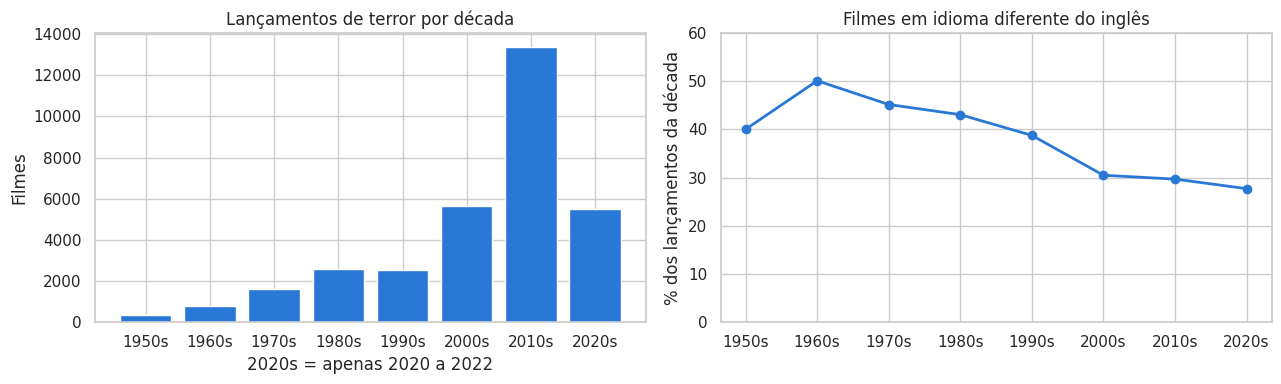

In [36]:
por_decada = df.groupby("decada").agg(
    filmes=("id", "size"),
    nao_ingles=("ingles", lambda serie: int((~serie).sum())),
)
por_decada["% não inglês"] = por_decada["nao_ingles"] / por_decada["filmes"] * 100
por_decada.index = [f"{decada}s" for decada in por_decada.index]
por_decada.index.name = "década"
display(por_decada.style.format({"filmes": "{:,}", "nao_ingles": "{:,}", "% não inglês": "{:.1f}%"}))

fig, (eixo_filmes, eixo_idioma) = plt.subplots(1, 2, figsize=(13, 4))
eixo_filmes.bar(por_decada.index, por_decada["filmes"], color=COR_PRINCIPAL)
eixo_filmes.set_title("Lançamentos de terror por década")
eixo_filmes.set_ylabel("Filmes")
eixo_filmes.set_xlabel("2020s = apenas 2020 a 2022")

eixo_idioma.plot(por_decada.index, por_decada["% não inglês"], color=COR_PRINCIPAL, linewidth=2, marker="o")
eixo_idioma.set_title("Filmes em idioma diferente do inglês")
eixo_idioma.set_ylabel("% dos lançamentos da década")
eixo_idioma.set_ylim(0, 60)
plt.tight_layout()
plt.show()

**Leitura:** os lançamentos cresceram em quase todas as décadas e explodiram a partir dos anos 2000. Só a década de 2010 tem 13.387 filmes, 41% da base. A década de 2020 parece menor porque cobre só 2020 a 2022, e em três anos já tem quase o mesmo número da década de 2000 inteira.

A participação de filmes em outros idiomas **caiu**: era metade dos lançamentos nos anos 1960 (50,1%) e ficou abaixo de um terço a partir dos anos 2000 (27,7% em 2020–2022). Em números absolutos os filmes em outros idiomas também cresceram, mas a produção em inglês cresceu mais rápido.

## P2 — Orçamento e avaliação

Pergunta: filmes de terror com maior orçamento recebem avaliações médias maiores do público?

Entram os filmes com orçamento informado e nota confiável. O orçamento é dividido em quatro faixas com a mesma quantidade aproximada de filmes (quartis), e a correlação de Spearman mede se a nota tende a subir junto com o orçamento sem ser dominada pelos orçamentos gigantes.

Filmes analisados: 2,122
Correlação de Spearman entre orçamento e nota: 0.31


,filmes,orcamento_min,orcamento_max,nota_media,nota_mediana
faixa de orçamento,,,,,
1 - mais baixo,584,"US$ 1,000","US$ 500,000",5.07,5.0
2,480,"US$ 520,000","US$ 2,300,000",5.29,5.3
3,528,"US$ 2,393,600","US$ 8,000,000",5.60,5.7
4 - mais alto,530,"US$ 8,300,000","US$ 200,000,000",5.96,6.0


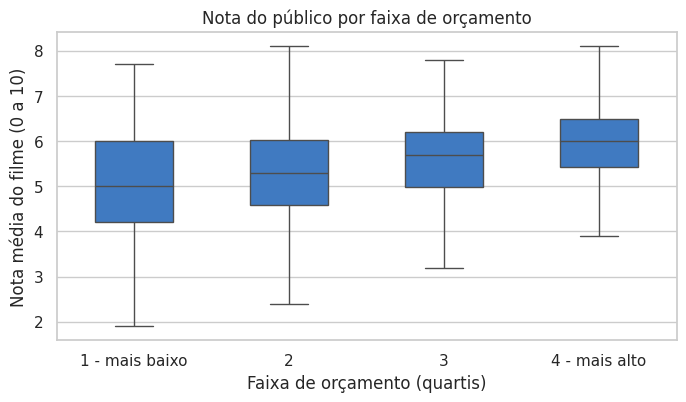

In [37]:
base_p2 = com_nota[com_nota["budget"].notna()].copy()
orcamento = base_p2["budget"].astype(float)
correlacao = orcamento.rank().corr(base_p2["vote_average"].rank())

FAIXAS = ["1 - mais baixo", "2", "3", "4 - mais alto"]
base_p2["faixa de orçamento"] = pd.qcut(orcamento, 4, labels=FAIXAS)
p2 = base_p2.groupby("faixa de orçamento", observed=True).agg(
    filmes=("id", "size"),
    orcamento_min=("budget", "min"),
    orcamento_max=("budget", "max"),
    nota_media=("vote_average", "mean"),
    nota_mediana=("vote_average", "median"),
)

print(f"Filmes analisados: {len(base_p2):,}")
print(f"Correlação de Spearman entre orçamento e nota: {correlacao:.2f}")
display(p2.style.format({
    "orcamento_min": "US$ {:,.0f}", "orcamento_max": "US$ {:,.0f}",
    "nota_media": "{:.2f}", "nota_mediana": "{:.1f}",
}))

plt.figure(figsize=(8, 4))
sns.boxplot(data=base_p2, x="faixa de orçamento", y="vote_average", color=COR_PRINCIPAL,
            showfliers=False, width=0.5)
plt.title("Nota do público por faixa de orçamento")
plt.xlabel("Faixa de orçamento (quartis)")
plt.ylabel("Nota média do filme (0 a 10)")
plt.show()

**Leitura:** sim, mas o efeito é pequeno. A nota média sobe a cada faixa, de 5,07 nos filmes mais baratos (até US$ 500 mil) para 5,96 nos mais caros (acima de US$ 8,3 milhões). A correlação de Spearman é 0,31, considerada fraca: as caixas do gráfico se sobrepõem bastante, e há muito filme barato com nota alta e filme caro com nota baixa.

Ter mais dinheiro ajuda um pouco, mas não garante uma avaliação melhor. A comparação vale para os 2.122 filmes que têm orçamento e nota confiável, cerca de 7% da base.

## P3 — Retorno proporcional por faixa de orçamento

Pergunta: entre os filmes com orçamento e receita informados, os de baixo orçamento apresentam retorno proporcional (receita/orçamento) maior que os de alto orçamento?

Usa a coluna `retorno` (receita ÷ orçamento), que só existe quando os dois valores são válidos. Retorno 2 significa que o filme faturou o dobro do que custou. Retorno acima de 1 é tratado como "receita maior que o orçamento", sem considerar marketing e distribuição, que a base não informa.

Filmes analisados: 1,010


,filmes,orcamento_min,orcamento_max,retorno_mediano,retorno_medio,pct_receita_maior
faixa de orçamento,,,,,,
1 - mais baixo,253,"US$ 1,000","US$ 1,800,000",3.08×,78.86×,70.8%
2,253,"US$ 1,900,000","US$ 6,500,000",2.00×,5.08×,63.2%
3,266,"US$ 6,600,000","US$ 17,000,000",2.13×,4.08×,68.4%
4 - mais alto,238,"US$ 18,000,000","US$ 200,000,000",2.03×,2.45×,73.5%


Maiores retornos da base:


title,ano,budget,revenue,retorno
One Cut of the Dead,2017,"US$ 30,000","US$ 200,000,000","6,667×"
The Blair Witch Project,1999,"US$ 60,000","US$ 248,639,099","4,144×"
Routs,2022,"US$ 25,000","US$ 50,000,000","2,000×"
Paranormal Activity,2007,"US$ 215,000","US$ 194,183,034",903×
Lady Frankenstein,1971,"US$ 200,000","US$ 139,683,000",698×


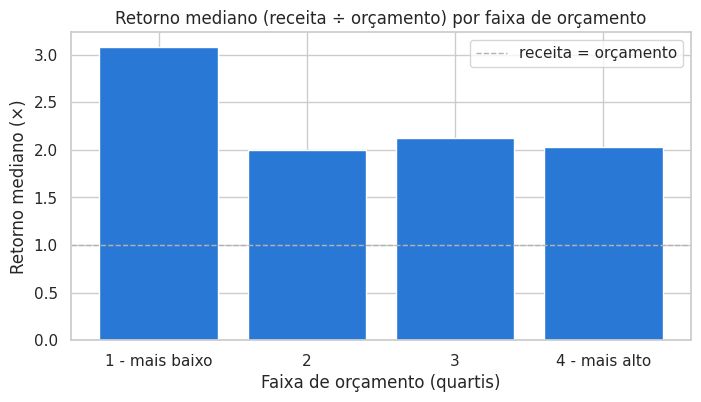

In [38]:
base_p3 = df[df["retorno"].notna()].copy()
base_p3["faixa de orçamento"] = pd.qcut(base_p3["budget"].astype(float), 4, labels=FAIXAS)
p3 = base_p3.groupby("faixa de orçamento", observed=True).agg(
    filmes=("id", "size"),
    orcamento_min=("budget", "min"),
    orcamento_max=("budget", "max"),
    retorno_mediano=("retorno", "median"),
    retorno_medio=("retorno", "mean"),
    pct_receita_maior=("retorno", lambda serie: (serie > 1).mean() * 100),
)

print(f"Filmes analisados: {len(base_p3):,}")
display(p3.style.format({
    "orcamento_min": "US$ {:,.0f}", "orcamento_max": "US$ {:,.0f}",
    "retorno_mediano": "{:.2f}×", "retorno_medio": "{:.2f}×", "pct_receita_maior": "{:.1f}%",
}))

print("Maiores retornos da base:")
display(
    base_p3.nlargest(5, "retorno")[["title", "ano", "budget", "revenue", "retorno"]]
    .style.hide(axis="index")
    .format({"budget": "US$ {:,.0f}", "revenue": "US$ {:,.0f}", "retorno": "{:,.0f}×"})
)

plt.figure(figsize=(8, 4))
plt.bar(p3.index.astype(str), p3["retorno_mediano"], color=COR_PRINCIPAL)
plt.axhline(1, color=COR_NEUTRA, linestyle="--", linewidth=1, label="receita = orçamento")
plt.legend(loc="upper right")
plt.title("Retorno mediano (receita ÷ orçamento) por faixa de orçamento")
plt.xlabel("Faixa de orçamento (quartis)")
plt.ylabel("Retorno mediano (×)")
plt.show()

**Leitura:** sim. O filme típico da faixa mais barata (até US$ 1,8 milhão) fatura 3,1 vezes o orçamento, contra cerca de 2 vezes nas outras três faixas. É também nessa faixa que estão os retornos extremos: *One Cut of the Dead* faturou 6.667 vezes o que custou, *A Bruxa de Blair* 4.144 vezes e *Atividade Paranormal* 903 vezes. Esses casos levam a média da faixa a 78,9×, por isso a mediana descreve melhor o filme típico.

O risco, porém, é parecido entre as faixas: de 63% a 74% dos filmes faturam mais do que custaram, e a faixa mais cara tem a maior proporção (73,5%). Filme barato tem potencial de retorno maior, não chance maior de se pagar.

Cuidado: só 1.010 filmes têm orçamento e receita, e filmes que deram certo têm mais chance de ter a bilheteria registrada. O retorno real dos filmes baratos provavelmente é menor do que o observado aqui.

## P4 — Gêneros combinados ao terror

Pergunta: quais gêneros aparecem com mais frequência combinados ao terror, e quais combinações têm melhor avaliação e popularidade?

Cada filme é desmembrado em uma linha por gênero (a lista já está sem repetições desde L7), e o próprio "Horror" é retirado. A comparação de nota e popularidade considera os gêneros que aparecem em pelo menos 300 filmes, para não destacar combinações raras.

Filmes classificados só como Horror: 12,422 (38.3%)


,filmes,% dos filmes,filmes_com_nota,nota_media,popularidade_mediana
genero,,,,,
Thriller,"7,640",23.6%,"3,293",5.42,1.63
Comedy,"4,940",15.2%,"1,190",5.49,0.88
Drama,"4,254",13.1%,"1,296",5.74,0.91
Mystery,"3,125",9.6%,"1,285",5.72,1.40
Science Fiction,"2,703",8.3%,"1,333",5.14,1.96
Fantasy,"2,188",6.8%,738,5.70,1.11
Action,"1,959",6.0%,826,5.22,1.65
Crime,"1,151",3.6%,426,5.65,1.40
Animation,972,3.0%,174,6.47,0.60


Combinações exatas mais comuns:


,filmes
genre_names,
Horror,12422
"Horror, Thriller",3241
"Comedy, Horror",2831
"Drama, Horror",1323
"Horror, Science Fiction",923
"Horror, Mystery, Thriller",859


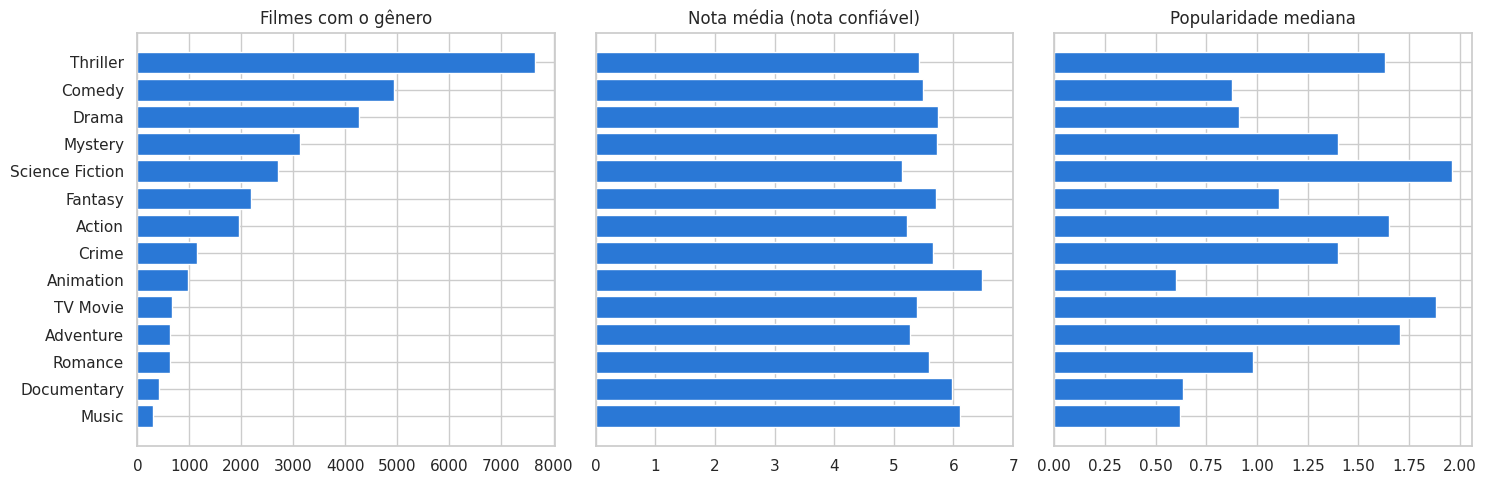

In [39]:
generos = (
    df.assign(genero=df["genre_names"].str.split(", "))
    .explode("genero")
    .query("genero != 'Horror'")
)
so_terror = int(df["genre_names"].eq("Horror").sum())
print(f"Filmes classificados só como Horror: {so_terror:,} ({so_terror / len(df):.1%})")

p4 = generos.groupby("genero").agg(
    filmes=("id", "size"),
    popularidade_mediana=("popularity", "median"),
).join(
    generos[generos["nota_confiavel"]].groupby("genero").agg(
        filmes_com_nota=("id", "size"),
        nota_media=("vote_average", "mean"),
    )
)
p4["% dos filmes"] = p4["filmes"] / len(df) * 100
p4 = p4[p4["filmes"].ge(300)].sort_values("filmes", ascending=False)

display(p4[["filmes", "% dos filmes", "filmes_com_nota", "nota_media", "popularidade_mediana"]].style.format({
    "filmes": "{:,}", "% dos filmes": "{:.1f}%", "filmes_com_nota": "{:,}",
    "nota_media": "{:.2f}", "popularidade_mediana": "{:.2f}",
}))

print("Combinações exatas mais comuns:")
display(df["genre_names"].value_counts().head(6).rename("filmes").to_frame())

fig, eixos = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
ordem = p4.index[::-1]
for eixo, coluna, titulo in zip(
    eixos,
    ["filmes", "nota_media", "popularidade_mediana"],
    ["Filmes com o gênero", "Nota média (nota confiável)", "Popularidade mediana"],
):
    eixo.barh(ordem, p4.loc[ordem, coluna], color=COR_PRINCIPAL)
    eixo.set_title(titulo)
eixos[1].set_xlim(0, 7)
plt.tight_layout()
plt.show()

**Leitura:** o parceiro mais comum do terror é o **Thriller** (7.640 filmes, 23,6% da base), seguido de **Comédia** (4.940), **Drama** (4.254) e **Mistério** (3.125). Ainda assim, a situação mais comum é não ter parceiro: 12.422 filmes (38,3%) são classificados só como terror.

**Melhor avaliação:** as combinações mais bem avaliadas são as menos frequentes. Animação (6,47), Música (6,12) e Documentário (5,97) lideram, e entre as combinações comuns o destaque é Drama (5,74) e Mistério (5,72).

**Maior popularidade:** é o lado oposto. Ficção científica (1,96), TV Movie (1,88), Aventura (1,71) e Ação (1,65) são as mais populares, mas estão entre as notas mais baixas (5,14 a 5,27). O terror de ação e ficção científica atrai mais público, e o terror de drama e animação é mais bem avaliado.

## P5 — Lançamentos em outubro

Pergunta: existe concentração de lançamentos em outubro (período do Halloween), e os filmes lançados nesse mês têm popularidade diferente dos demais?

Antes de contar por mês, é preciso separar as datas de **1º de janeiro**. O TMDB grava essa data quando só o ano do lançamento é conhecido, e ela inflaria janeiro artificialmente. Esses filmes ficam fora apenas desta pergunta; a base limpa não muda.

Filmes com data em 1º de janeiro: 3,836 de 5,582 lançados em janeiro
Lançados exatamente em 31 de outubro: 503


,filmes,popularidade_mediana,popularidade_media,nota_media,filmes por mês
periodo,,,,,
outros meses,"23,798",0.88,4.50,5.37,"2,163"
outubro,"4,770",0.84,3.83,5.39,"4,770"


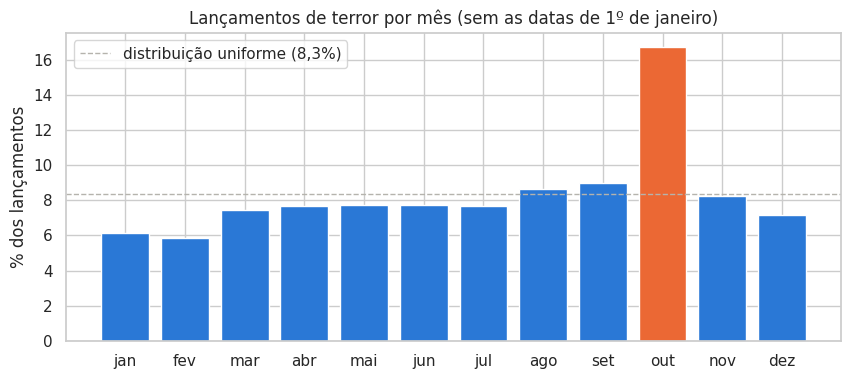

In [40]:
primeiro_janeiro = df["release_date"].dt.month.eq(1) & df["release_date"].dt.day.eq(1)
print(f"Filmes com data em 1º de janeiro: {int(primeiro_janeiro.sum()):,} "
      f"de {int(df['mes'].eq(1).sum()):,} lançados em janeiro")

base_p5 = df[~primeiro_janeiro].copy()
base_p5["periodo"] = np.where(base_p5["mes"].eq(10), "outubro", "outros meses")

nomes_meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
por_mes = base_p5["mes"].value_counts(normalize=True).sort_index().mul(100)
por_mes.index = nomes_meses

outubro_31 = int((base_p5["mes"].eq(10) & base_p5["release_date"].dt.day.eq(31)).sum())
print(f"Lançados exatamente em 31 de outubro: {outubro_31:,}")

p5 = base_p5.groupby("periodo").agg(
    filmes=("id", "size"),
    popularidade_mediana=("popularity", "median"),
    popularidade_media=("popularity", "mean"),
).join(base_p5[base_p5["nota_confiavel"]].groupby("periodo").agg(nota_media=("vote_average", "mean")))
p5["filmes por mês"] = p5["filmes"] / np.where(p5.index == "outubro", 1, 11)
display(p5.style.format({
    "filmes": "{:,}", "filmes por mês": "{:,.0f}", "popularidade_mediana": "{:.2f}",
    "popularidade_media": "{:.2f}", "nota_media": "{:.2f}",
}))

plt.figure(figsize=(10, 4))
plt.bar(por_mes.index, por_mes.values,
        color=[COR_DESTAQUE if mes == "out" else COR_PRINCIPAL for mes in por_mes.index])
plt.axhline(100 / 12, color=COR_NEUTRA, linestyle="--", linewidth=1, label="distribuição uniforme (8,3%)")
plt.legend(loc="upper left")
plt.title("Lançamentos de terror por mês (sem as datas de 1º de janeiro)")
plt.ylabel("% dos lançamentos")
plt.show()

**Leitura:** sim, existe concentração. Sem as 3.836 datas de 1º de janeiro, outubro reúne 16,7% dos lançamentos, o dobro do que teria se os filmes fossem distribuídos igualmente pelos meses (8,3%) e quase o dobro do segundo colocado, setembro (9,0%). Só no dia 31 de outubro foram lançados 503 filmes.

A popularidade, porém, **não é maior**: os filmes de outubro são até um pouco menos populares que os dos outros meses (mediana de 0,84 contra 0,88, média de 3,83 contra 4,50). Uma explicação possível é a concorrência: com o dobro de lançamentos no mesmo mês, cada filme divide a atenção do público com mais títulos. A nota fica no mesmo nível (5,39 contra 5,37). Os estúdios lançam mais filmes no Halloween, mas lançar em outubro não deixa o filme mais popular nem mais bem avaliado.

## P6 — Filmes de franquia e filmes avulsos

Pergunta: filmes que pertencem a uma franquia têm avaliação e receita diferentes de filmes avulsos?

Usa a flag `franquia` (criada em L11 a partir de `collection`). A nota considera só notas confiáveis, e a receita e o retorno só os filmes com o valor informado.

,filmes,filmes com nota,nota média,filmes com receita,receita mediana,retorno mediano,popularidade mediana
franquia,"2,302","1,447",5.50,467,"US$ 22,000,000",3.52×,3.80
avulso,"30,102","7,030",5.32,"1,016","US$ 2,064,798",1.22×,0.71


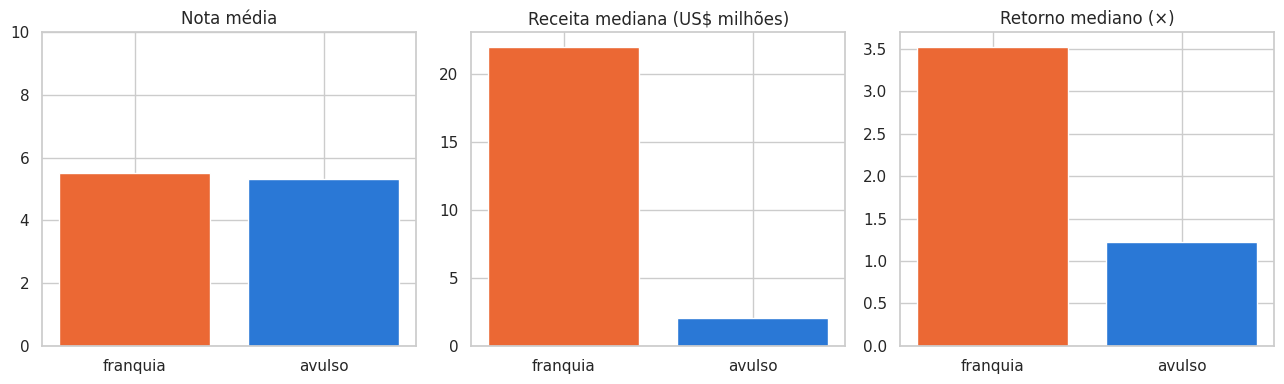

In [41]:
grupos = {True: "franquia", False: "avulso"}
p6 = pd.DataFrame({
    "filmes": df.groupby("franquia")["id"].size(),
    "filmes com nota": com_nota.groupby("franquia")["id"].size(),
    "nota média": com_nota.groupby("franquia")["vote_average"].mean(),
    "filmes com receita": df[df["revenue"].notna()].groupby("franquia")["id"].size(),
    "receita mediana": df.groupby("franquia")["revenue"].median(),
    "retorno mediano": df.groupby("franquia")["retorno"].median(),
    "popularidade mediana": df.groupby("franquia")["popularity"].median(),
}).rename(index=grupos).loc[["franquia", "avulso"]].rename_axis(None)

display(p6.style.format({
    "filmes": "{:,}", "filmes com nota": "{:,}", "nota média": "{:.2f}", "filmes com receita": "{:,}",
    "receita mediana": "US$ {:,.0f}", "retorno mediano": "{:.2f}×", "popularidade mediana": "{:.2f}",
}))

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
cores = [COR_DESTAQUE, COR_PRINCIPAL]
for eixo, coluna, titulo, escala in zip(
    eixos,
    ["nota média", "receita mediana", "retorno mediano"],
    ["Nota média", "Receita mediana (US$ milhões)", "Retorno mediano (×)"],
    [1, 1e6, 1],
):
    eixo.bar(p6.index, p6[coluna] / escala, color=cores)
    eixo.set_title(titulo)
eixos[0].set_ylim(0, 10)
plt.tight_layout()
plt.show()

**Leitura:** na avaliação, a diferença é pequena: 5,50 para filmes de franquia contra 5,32 para avulsos. Na receita, a diferença é grande: o filme de franquia típico fatura US$ 22 milhões, cerca de dez vezes os US$ 2,1 milhões do avulso típico, e o retorno mediano é 3,5× contra 1,2×. Filmes de franquia também são bem mais populares (mediana de 3,80 contra 0,71).

Em resumo, pertencer a uma franquia quase não muda a opinião do público, mas muda muito o resultado financeiro. Parte disso é seleção: uma franquia só continua quando os primeiros filmes deram dinheiro.

## Síntese das respostas

| Pergunta | Resposta |
|---|---|
| **P1** Lançamentos por década e idiomas | Os lançamentos cresceram muito a partir dos anos 2000 (13.387 filmes na década de 2010). A participação de outros idiomas caiu de 50% nos anos 1960 para menos de 30% a partir dos anos 2000. |
| **P2** Orçamento × nota | A nota sobe com o orçamento (5,07 → 5,96 entre a faixa mais baixa e a mais alta), mas a relação é fraca (Spearman 0,31). |
| **P3** Retorno por orçamento | Sim: a faixa mais barata tem retorno mediano de 3,1×, contra cerca de 2× nas outras. A proporção de filmes que se pagam é parecida em todas as faixas. |
| **P4** Gêneros combinados | Thriller, Comédia, Drama e Mistério são os mais frequentes. Animação e Drama têm as melhores notas; Ficção científica e Ação, a maior popularidade. |
| **P5** Outubro | Sim: outubro concentra 16,7% dos lançamentos, o dobro da média. Os filmes de outubro não são mais populares (mediana 0,84 × 0,88) nem mais bem avaliados (5,39 × 5,37). |
| **P6** Franquia × avulso | Nota quase igual (5,50 × 5,32); receita mediana cerca de dez vezes maior (US$ 22 mi × US$ 2,1 mi) e retorno maior (3,5× × 1,2×). |

**Limites das respostas:**
- Orçamento e receita existem para poucos filmes (2.122 com orçamento e nota; 1.010 com retorno), então P2, P3 e a parte financeira de P6 valem para essa amostra, que tende a ter filmes maiores e mais bem-sucedidos.
- A década de 2020 cobre apenas 2020 a 2022.
- Popularidade e notas são do TMDB em outubro de 2022, e não da bilheteria oficial ou da crítica.